# Reading the dataset

In [1]:
# import library and read dataset

import pandas as pd

df_reviews = pd.read_csv('IMDB Dataset.csv')


In [ ]:
df_reviews.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# take a sample of 10000 rows to make processing faster and get imbalance data
# 9000 positives
df_positive = df_reviews[df_reviews['sentiment']=='positive'][:9000]
# 1000 negative
df_negative = df_reviews[df_reviews['sentiment']=='negative'][:1000]


In [6]:
df_reviews_imb = pd.concat([df_positive, df_negative])


In [7]:
df_reviews_imb.value_counts('sentiment')


sentiment
positive    9000
negative    1000
Name: count, dtype: int64

# Dealing with Imbalanced Classes

<Axes: xlabel='sentiment'>

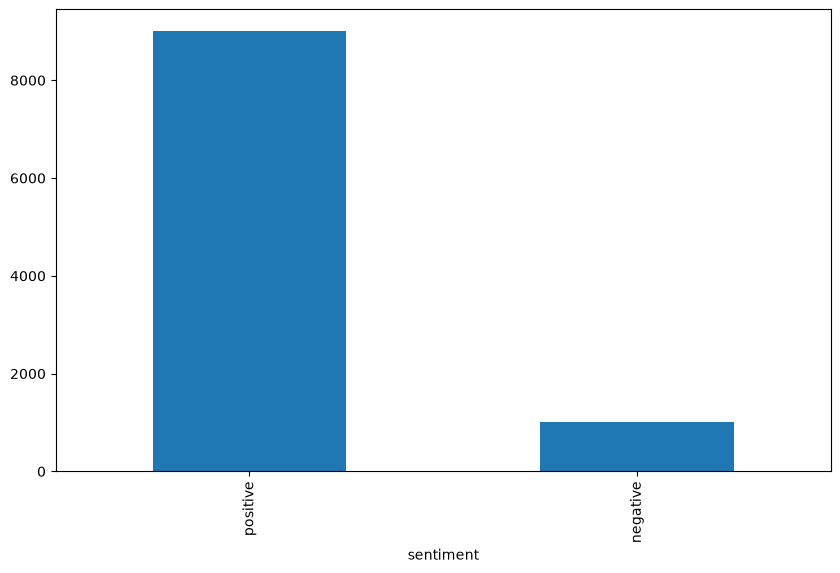

In [8]:
# make a barplot to show how data is distributed
df_reviews_imb.value_counts('sentiment').plot(kind='bar', figsize=(10,6))


# Balancing data with .sample()

In [9]:
length_negative = len(df_reviews_imb[df_reviews_imb['sentiment']=='negative'])


In [ ]:
df_reviews_positive = df_reviews_imb[df_reviews_imb['sentiment']=='positive'].sample(n=length_negative)


In [11]:
df_reviews_negative = df_reviews_imb[df_reviews_imb['sentiment']=='negative']


In [ ]:
df_reviews_bal = pd.concat([df_reviews_positive, df_reviews_negative])


In [13]:
df_reviews_bal.reset_index(drop=True, inplace=True)


In [14]:
df_reviews_bal.value_counts('sentiment')


sentiment
positive    1000
negative    1000
Name: count, dtype: int64

# Balancing data with RandomUnderSampler

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=0)

df_reviews_bal, df_reviews_bal['sentiment'] = rus.fit_resample(df_reviews_imb[['review']],
                                                             df_reviews_imb['sentiment'])


(                                                  review
 3      Basically there's a family where a little boy ...
 7      This show was an amazing, fresh & innovative i...
 8      Encouraged by the positive comments about this...
 10     Phil the Alien is one of those quirky films wh...
 11     I saw this movie when I was about 12 when it c...
 ...                                                  ...
 10833  Knute Rockne led an extraordinary life and his...
 1039   At the height of the 'Celebrity Big Brother' r...
 5255   This is another of Robert Altman's underrated ...
 12237  This movie won a special award at Cannes for i...
 15014  You'd be forgiven to think a Finnish director ...
 
 [2000 rows x 1 columns],
 3        negative
 7        negative
 8        negative
 10       negative
 11       negative
            ...   
 10833    positive
 1039     positive
 5255     positive
 12237    positive
 15014    positive
 Name: sentiment, Length: 2000, dtype: str)

In [18]:

df_reviews_bal['sentiment'].value_counts()


sentiment
positive    1000
negative    1000
Name: count, dtype: int64

In [19]:

df_reviews_imb['sentiment'].value_counts()


sentiment
positive    9000
negative    1000
Name: count, dtype: int64

# Splitting data into train and test

In [20]:
# import train_test_split
from sklearn.model_selection import train_test_split
train, test = train_test_split(df_reviews_bal, test_size=0.33, random_state=44)


In [ ]:
train


,review,sentiment
97,"As one other IMDb reviewer puts it, ""...imagin...",positive
1274,"I am a huge fan of the Farcry Game, HUGE fan. ...",negative
233,Love and war did happen on the other side of t...,positive
1312,Although promoted as one of the most sincere T...,negative
1323,It starts out like a very serious social comme...,negative
...,...,...
571,This is the start of a new and interesting Sta...,positive
1197,This movie illustrates like no other the state...,negative
753,If you are a fan of Altman's large ensemble ca...,positive
1443,How can so many blundering decisions can be ma...,negative


In [ ]:
test


,review,sentiment
870,A brilliant Russian émigré devises the Stanis...,positive
1059,It is easy to tell early in this movie exactly...,negative
1440,Largely forgettable tale in which mercenary Ke...,negative
1636,"Ladies and Gentlemen, may we present the worst...",negative
68,I saw the movie in Izmir as the closing film o...,positive
...,...,...
88,Handsome and dashing British airline pilot Geo...,positive
526,A top notch Columbo from beginning to end. I p...,positive
1948,"A very hyped-up, slick, edgy reinterpretation....",negative
76,This movie is breath-taking and mind-blowing. ...,positive


In [23]:
train_x, train_y = train['review'], train['sentiment']
test_x, test_y = test['review'], test['sentiment']


In [24]:
train_x
train_y.value_counts()



sentiment
positive    672
negative    668
Name: count, dtype: int64

# Text Representation (Bag of Words)

#  Count Vectorizer
### This technique is called Bag-of-Words (BoW) (or Text Vectorization), and the resulting output matrix (cv_matrix) is called a Document-Term Matrix (DTM).

In [25]:
from sklearn.feature_extraction.text import CountVectorizer

text = ["I love writing code in Python. I love Python code",
        "I hate writing code in Java. I hate Java code"]

df = pd.DataFrame({'review':['review1', 'review2'], 'text':text})
cv = CountVectorizer(stop_words='english')
cv_matrix = cv.fit_transform(df['text'])


In [27]:
df_tdm = pd.DataFrame(cv_matrix.toarray(), index=df['review'].values, columns=cv.get_feature_names_out())


In [ ]:
df_tdm


,code,hate,java,love,python,writing
review1,2,0,0,2,2,1
review2,2,2,2,0,0,1


# TFIDF

# TF-IDF
## TF-IDF=TF*IDF
## IDF = log(total number of sentences + 1 / number of sentences containing the word + 1) +1

### TF-IDF1 = TF1 * IDF1
### TF-IDF2 = TF2 * IDF2

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

text = ["I love writing code in Python. I love Python code",
        "I hate writing code in Java. I hate Java code"]

df = pd.DataFrame({'review':['review1', 'review2'], 'text':text})
tfidf = TfidfVectorizer(stop_words='english', norm=None)
tfidf_matrix = tfidf.fit_transform(df['text'])


In [31]:
pd.DataFrame(tfidf_matrix.toarray(), index=df['review'].values,
                      columns=tfidf.get_feature_names_out())


,code,hate,java,love,python,writing
review1,2.0,0.00000,0.00000,2.81093,2.81093,1.0
review2,2.0,2.81093,2.81093,0.00000,0.00000,1.0


# Turning our text data into numerical vectors

In [32]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')
train_x_vector = tfidf.fit_transform(train_x)


In [ ]:
test_x_vector = tfidf.transform(test_x)


In [ ]:
train_x_vector


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 118234 stored elements and shape (1340, 20422)>

In [36]:
pd.DataFrame.sparse.from_spmatrix(train_x_vector,
                                  index=train_x.index,
                                  columns=tfidf.get_feature_names_out())


,00,000,007,01,02,04,05,10,100,1000,...,zoom,zooming,zooms,zor,zu,zucher,zucker,zuniga,zzzzzzzzzzzzzzzzzz,ísnt
97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1274,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.033338,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
233,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1312,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1323,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
753,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1443,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Model Selection

# Support Vector Machines (SVM)

# Decision Tree

# Naive Bayes

# Logistic Regression